# Лабораторная работа №3. Регрессионный анализ
**Вариант 13** · ФИО: __________________ · Группа: __________________

**Цель:** изучить простую и полиномиальную регрессию, сравнить линейную регрессию, kNN и дерево решений в задаче прогноза годовой зарплаты.

Работа содержит три части из методички. В каждой части сначала приведены пояснения, затем код и интерпретация результатов.

**Вариант:** по согласованному циклическому правилу для варианта 13 используется лист `var3`: (13 − 1) % 10 + 1 = 3.

**Запуск в Colab:** загрузите этот ноутбук через «Файл → Загрузить блокнот», выполните ячейки по порядку и загрузите оба файла данных по запросу. Часть 3 также можно запускать отдельно после первой ячейки загрузки данных и библиотек.


## 1. Загрузка данных и библиотек


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42  # Фиксируем разбиение для воспроизводимости.
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

# В Colab файлы можно выбрать с компьютера. Локально положите их рядом с ноутбуком.
try:
    from google.colab import files
    if not list(Path('.').glob('regression*.xlsx')) or not Path('salary.csv').exists():
        uploaded = files.upload()
except ImportError:
    pass

excel_files = sorted(Path('.').glob('regression*.xlsx'))
if not excel_files or not Path('salary.csv').exists():
    raise FileNotFoundError('Загрузите regression (1).xlsx и salary.csv в папку ноутбука.')
excel_path = excel_files[0]
salary = pd.read_csv('salary.csv')
print('Листы Excel:', pd.ExcelFile(excel_path).sheet_names)
print('Размер salary:', salary.shape)

# Общие инструменты: часть 3 можно выполнить независимо от выбора листа Excel.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def regression_metrics(y_true, prediction):
    mse = mean_squared_error(y_true, prediction)
    return {'MAE': mean_absolute_error(y_true, prediction),
            'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, prediction)}


Листы Excel: ['var1', 'var2', 'var3', 'var4', 'var5', 'var6', 'var7', 'var8', 'var9', 'var10']
Размер salary: (1500, 15)


## Часть 1. Простая линейная регрессия
### 1.1. Выбор листа и обзор данных
В каждом листе Excel 1000 наблюдений. `x1`, `x2` — количественные признаки, `y` — целевая переменная. Предметный смысл и единицы измерения этих синтетических признаков не указаны.

Для варианта 13 используем `var3` по согласованному циклическому правилу.


Выбран лист: var3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
 2   y       1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB
Пропуски: {'x1': 0, 'x2': 0, 'y': 0}
Дубликаты: 0
x1 и y: r = 0.000, слабая линейная связь, прямая.
x2 и y: r = 0.850, сильная линейная связь, прямая.


,x1,x2,y
0,1.696315,-0.548550,0.870770
1,-0.560186,1.176442,0.539647
2,1.493260,0.386962,1.049902
3,0.162986,-1.232673,-1.490034
4,0.344845,0.740232,1.737131
5,1.756825,1.342264,3.748636
6,-1.234110,0.665019,0.988839
7,0.853258,-1.163597,-0.842644
8,0.318094,-0.487262,-0.704140
9,1.779796,-1.369448,0.244140


,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,0.000007,-0.000038,0.483917
std,1.155357,1.155261,1.670779
min,-1.998745,-1.996808,-3.498375
25%,-0.998825,-0.999651,-0.774310
50%,0.000264,0.001129,0.434032
75%,0.997258,0.998857,1.741084
max,1.997294,1.997547,5.060642


,x1,x2,y
x1,1.000000,0.010576,0.000333
x2,0.010576,1.000000,0.849765
y,0.000333,0.849765,1.000000


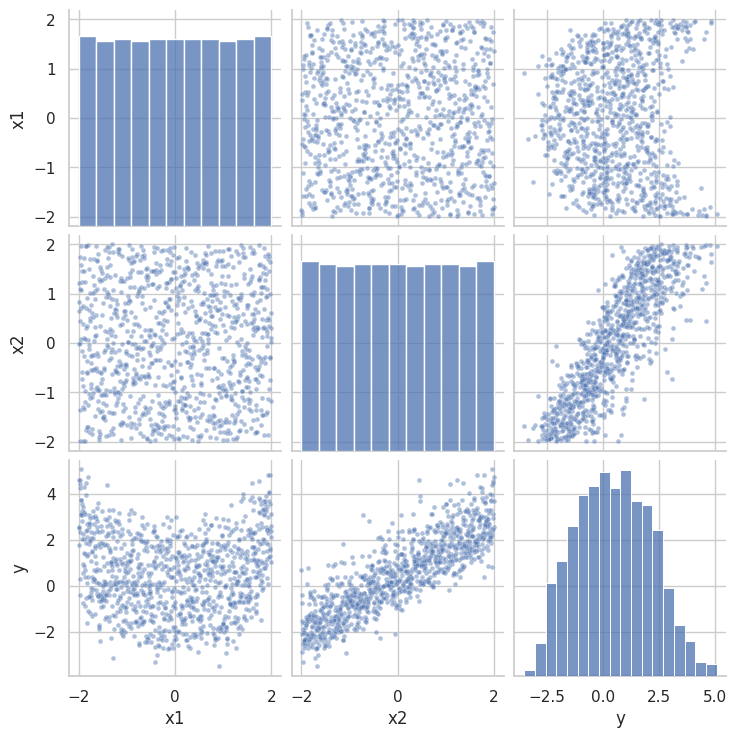

In [2]:
SHEET_NAME = 'var3'  # Вариант 13: согласованный циклический выбор листа.
if SHEET_NAME not in pd.ExcelFile(excel_path).sheet_names:
    raise ValueError('Листа нет в файле. Уточните соответствие варианта и листа.')
reg = pd.read_excel(excel_path, sheet_name=SHEET_NAME)
print('Выбран лист:', SHEET_NAME)
display(reg.head(20))
reg.info()
display(reg.describe())
print('Пропуски:', reg.isna().sum().to_dict())
print('Дубликаты:', reg.duplicated().sum())
assert reg[['x1', 'x2', 'y']].notna().all().all(), 'Обнаружены пропуски: нужна обработка.'
corr = reg.corr(method='pearson')
display(corr)
for feature in ['x1', 'x2']:
    r = corr.loc[feature, 'y']
    strength = 'слабая' if abs(r) < 0.3 else ('умеренная' if abs(r) < 0.7 else 'сильная')
    print(f'{feature} и y: r = {r:.3f}, {strength} линейная связь, '
          f'{"прямая" if r >= 0 else "обратная"}.')
sns.pairplot(reg[['x1', 'x2', 'y']], plot_kws={'s': 12, 'alpha': .45})
plt.show()


**Предварительный вывод.** Знак корреляции показывает направление линейной связи, модуль — её выраженность. Указанные границы силы связи условны. Слабая корреляция не исключает нелинейную зависимость, поэтому вместе с коэффициентами рассматриваю диаграммы рассеяния.


### 1.2. Обучение, прогнозы и метрики
Использую одно разбиение индексов: 75% наблюдений для обучения, 25% для валидации. Обе парные регрессии сравниваются на одинаковых строках. Для каждой модели выводятся все прогнозы, коэффициенты и четыре метрики.

MAE — средняя абсолютная ошибка, MSE — средний квадрат ошибки, RMSE — корень из MSE в единицах `y`. Чем они меньше, тем лучше. R² сравнивает модель с прогнозом среднего значения целевой переменной на оцениваемой выборке; максимум равен 1, отрицательное значение означает результат хуже этого ориентира.


In [3]:
train_idx, valid_idx = train_test_split(reg.index, test_size=.25, random_state=RANDOM_STATE)
y_train_reg = reg.loc[train_idx, 'y']
y_valid_reg = reg.loc[valid_idx, 'y']
linear_models = {}
linear_rows = []
linear_predictions = {}
for feature in ['x1', 'x2']:
    model = LinearRegression()
    model.fit(reg.loc[train_idx, [feature]], y_train_reg)
    pred = model.predict(reg.loc[valid_idx, [feature]])
    linear_models[feature] = model
    linear_predictions[feature] = pred
    linear_rows.append({'Признак': feature, **regression_metrics(y_valid_reg, pred)})
    comparison = pd.DataFrame({'Истинное y': y_valid_reg, 'Прогноз': pred})
    comparison['Прогноз − факт'] = comparison['Прогноз'] - comparison['Истинное y']
    print(f'Модель по {feature}: y = {model.coef_[0]:.6f} * {feature} '
          f'{model.intercept_:+.6f}')
    with pd.option_context('display.max_rows', None):
        display(comparison.sort_index())
linear_results = pd.DataFrame(linear_rows).set_index('Признак')
display(linear_results)
print('Лучше на валидации по RMSE:', linear_results['RMSE'].idxmin())


Модель по x1: y = -0.031991 * x1 +0.450302
Модель по x2: y = 1.216848 * x2 +0.459898
Лучше на валидации по RMSE: x2


,Истинное y,Прогноз,Прогноз − факт
2,1.049902,0.402531,-0.647371
3,-1.490034,0.445088,1.935122
10,2.025431,0.455829,-1.569602
23,-1.819759,0.433458,2.253217
25,4.607668,0.513399,-4.094269
29,0.501901,0.434531,-0.067369
30,3.285727,0.494037,-2.791690
31,-0.787755,0.413982,1.201737
33,2.874938,0.489942,-2.384997
39,0.572998,0.403627,-0.169370


,Истинное y,Прогноз,Прогноз − факт
2,1.049902,0.930771,-0.119131
3,-1.490034,-1.040077,0.449957
10,2.025431,2.762180,0.736749
23,-1.819759,-0.992527,0.827232
25,4.607668,1.001304,-3.606364
29,0.501901,0.276615,-0.225286
30,3.285727,2.821461,-0.464265
31,-0.787755,-1.772563,-0.984808
33,2.874938,2.149737,-0.725202
39,0.572998,0.193730,-0.379268


,MAE,MSE,RMSE,R2
Признак,,,,
x1,1.455234,3.075470,1.753702,-0.008890
x2,0.696717,0.823589,0.907518,0.729827


### 1.3. Линии регрессии, ошибки по наблюдениям и факт–прогноз


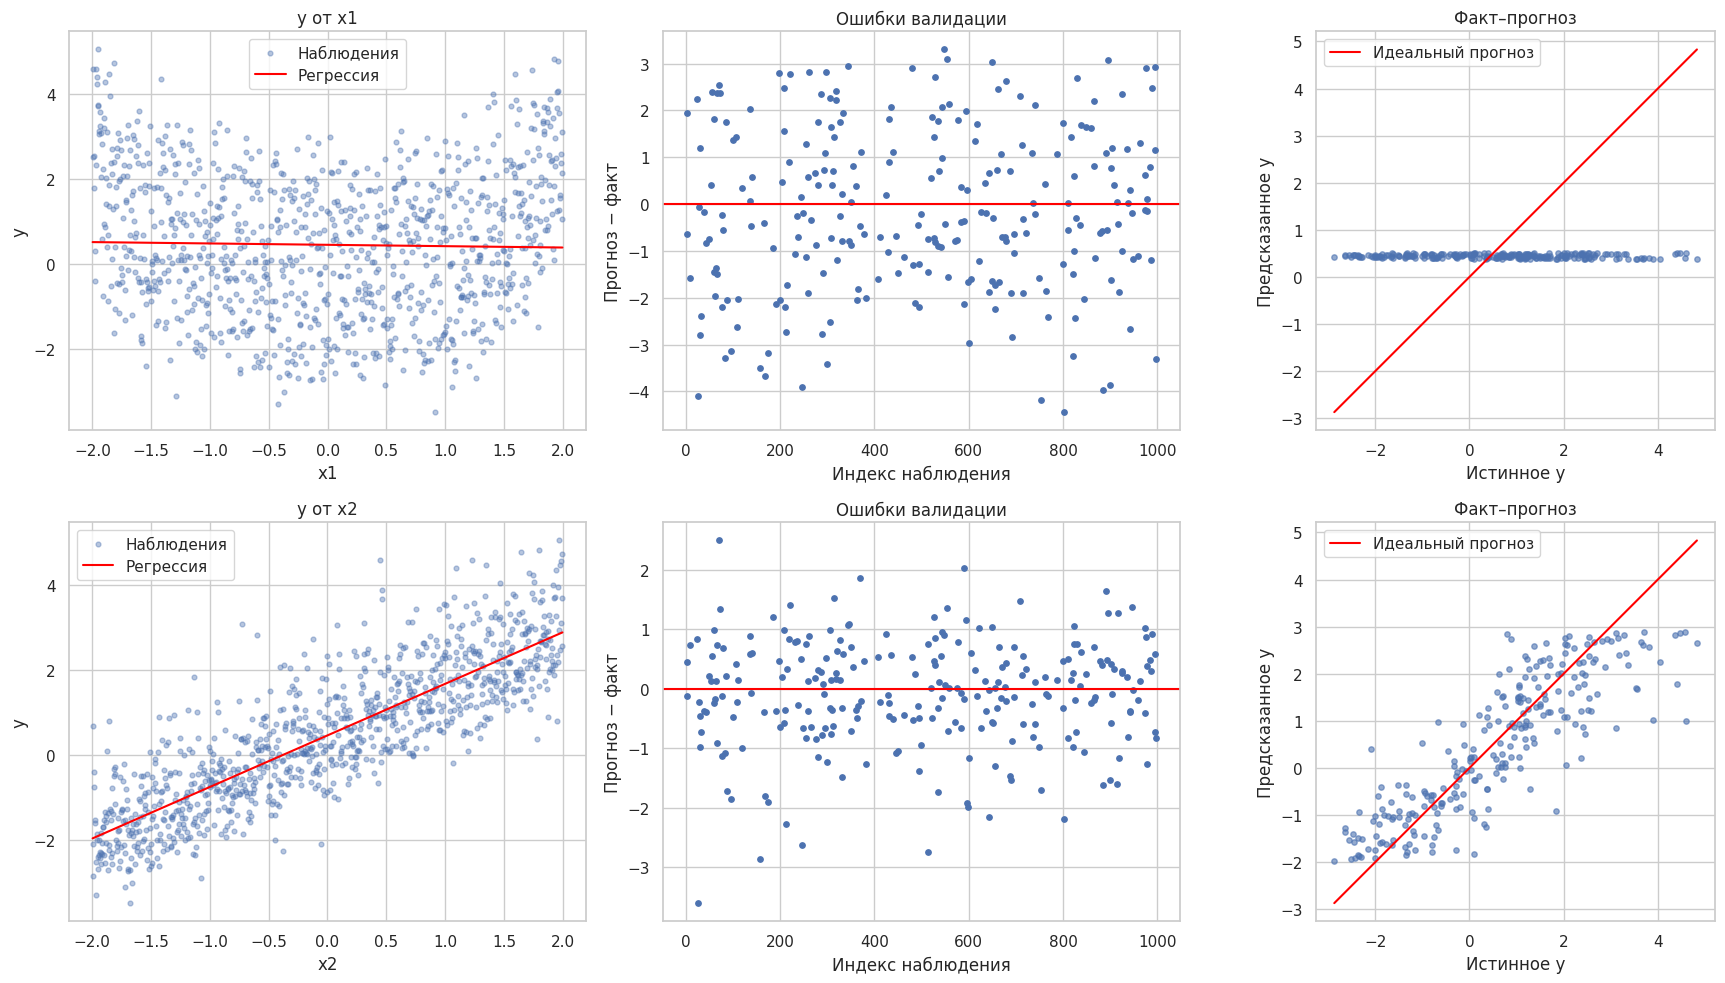

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, feature in enumerate(['x1', 'x2']):
    model = linear_models[feature]
    grid = pd.DataFrame({feature: np.linspace(reg[feature].min(), reg[feature].max(), 300)})
    axes[row, 0].scatter(reg[feature], reg['y'], s=12, alpha=.4, label='Наблюдения')
    axes[row, 0].plot(grid[feature], model.predict(grid), color='red', label='Регрессия')
    axes[row, 0].set(xlabel=feature, ylabel='y', title=f'y от {feature}')
    axes[row, 0].legend()
    pred = linear_predictions[feature]
    # Сортируем по исходному индексу: точки соответствуют одним и тем же объектам.
    errors = pd.Series(pred - y_valid_reg.to_numpy(), index=valid_idx).sort_index()
    axes[row, 1].scatter(errors.index, errors, s=15)
    axes[row, 1].axhline(0, color='red')
    axes[row, 1].set(xlabel='Индекс наблюдения', ylabel='Прогноз − факт', title='Ошибки валидации')
    lo, hi = min(y_valid_reg.min(), pred.min()), max(y_valid_reg.max(), pred.max())
    axes[row, 2].scatter(y_valid_reg, pred, s=15, alpha=.6)
    axes[row, 2].plot([lo, hi], [lo, hi], color='red', label='Идеальный прогноз')
    axes[row, 2].set(xlabel='Истинное y', ylabel='Предсказанное y', title='Факт–прогноз')
    axes[row, 2].set_aspect('equal', adjustable='box')
    axes[row, 2].legend()
plt.tight_layout()
plt.show()


**Вывод по части 1.** Для var3 корреляция x1 и y практически нулевая (r ≈ 0,0003), а x2 и y связаны сильно и положительно (r ≈ 0,850). Модель по x2 лучше: R² valid ≈ 0,730 и MAE ≈ 0,697 против R² ≈ −0,009 и MAE ≈ 1,455 для x1. Линия по x2 имеет вид y ≈ 1,21685·x2 + 0,45990. Поэтому для парной линейной регрессии выбираю x2. Остатки отражают разброс, который одним признаком объяснить не удалось. Эти связи не доказывают причинность.


## Часть 2. Полиномиальная регрессия
### 2.1. Выбор признака и степени
Сравню степени 1, 2, 3, 5 и 10 отдельно для обоих признаков. Степень 1 служит ориентиром. Признак и степень выбираю по средней MAE на пяти фолдах **внутри обучающей выборки**. Так валидационные строки не участвуют в подборе. Нелинейную модель имеет смысл предпочесть, если она уменьшает ошибку относительно степени 1. Масштабирование включено в Pipeline и обучается отдельно на каждом фолде.

После выбора показываю учебное сравнение разных степеней на том же отложенном наборе. Это валидационная оценка, а не независимый итоговый тест.


In [5]:
degrees = [1, 2, 3, 5, 10]
poly_searches = {}
cv_rows = []
for feature in ['x1', 'x2']:
    pipeline = make_pipeline(PolynomialFeatures(include_bias=False),
                             StandardScaler(), LinearRegression())
    search = GridSearchCV(pipeline, {'polynomialfeatures__degree': degrees},
                          scoring='neg_mean_absolute_error', cv=cv, n_jobs=1)
    search.fit(reg.loc[train_idx, [feature]], y_train_reg)
    poly_searches[feature] = search
    for params, score in zip(search.cv_results_['params'], search.cv_results_['mean_test_score']):
        cv_rows.append({'Признак': feature, 'Степень': params['polynomialfeatures__degree'],
                        'MAE CV': -score})
cv_results = pd.DataFrame(cv_rows)
display(cv_results)
best_feature = min(poly_searches, key=lambda name: -poly_searches[name].best_score_)
best_degree = poly_searches[best_feature].best_params_['polynomialfeatures__degree']
print('Выбор только по обучающим данным:', best_feature, ', степень', best_degree)
for feature in ['x1', 'x2']:
    part = cv_results[cv_results['Признак'] == feature]
    base = part.loc[part['Степень'] == 1, 'MAE CV'].iloc[0]
    nonlinear = part.loc[part['Степень'] > 1, 'MAE CV'].min()
    print(f'{feature}: MAE CV линейной = {base:.4f}, лучшей нелинейной = {nonlinear:.4f}')
poly_models = {}
poly_rows = []
for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    model.fit(reg.loc[train_idx, [best_feature]], y_train_reg)
    train_pred = model.predict(reg.loc[train_idx, [best_feature]])
    valid_pred = model.predict(reg.loc[valid_idx, [best_feature]])
    poly_models[degree] = model
    poly_rows.append({'Степень': degree,
                     'R2 train': r2_score(y_train_reg, train_pred),
                     'R2 valid': r2_score(y_valid_reg, valid_pred),
                     'MAE train': mean_absolute_error(y_train_reg, train_pred),
                     'MAE valid': mean_absolute_error(y_valid_reg, valid_pred)})
poly_results = pd.DataFrame(poly_rows).set_index('Степень')
display(poly_results)
selected_poly = poly_models[best_degree]
poly_pred = selected_poly.predict(reg.loc[valid_idx, [best_feature]])
display(pd.DataFrame({'Факт': y_valid_reg, 'Прогноз': poly_pred}).head(20))


Выбор только по обучающим данным: x2 , степень 2
x1: MAE CV линейной = 1.3681, лучшей нелинейной = 1.2726
x2: MAE CV линейной = 0.6887, лучшей нелинейной = 0.6885


,Признак,Степень,MAE CV
0,x1,1,1.368069
1,x1,2,1.289512
2,x1,3,1.291365
3,x1,5,1.274534
4,x1,10,1.272616
5,x2,1,0.688673
6,x2,2,0.688496
7,x2,3,0.688535
8,x2,5,0.692759
9,x2,10,0.697959


,R2 train,R2 valid,MAE train,MAE valid
Степень,,,,
1,0.718363,0.729827,0.686203,0.696717
2,0.718418,0.729167,0.685776,0.698166
3,0.718420,0.729191,0.685769,0.698246
5,0.718606,0.729368,0.686382,0.697588
10,0.720813,0.726254,0.685504,0.701811


,Факт,Прогноз
521,-0.068690,-0.072733
737,0.373671,-0.447062
740,-1.625924,-1.506173
660,-0.280631,-0.620072
411,1.089776,0.847241
678,-2.158199,-1.701565
626,0.561486,-0.119271
513,1.837413,-0.918179
859,-1.183537,-1.418152
136,0.385483,1.268524


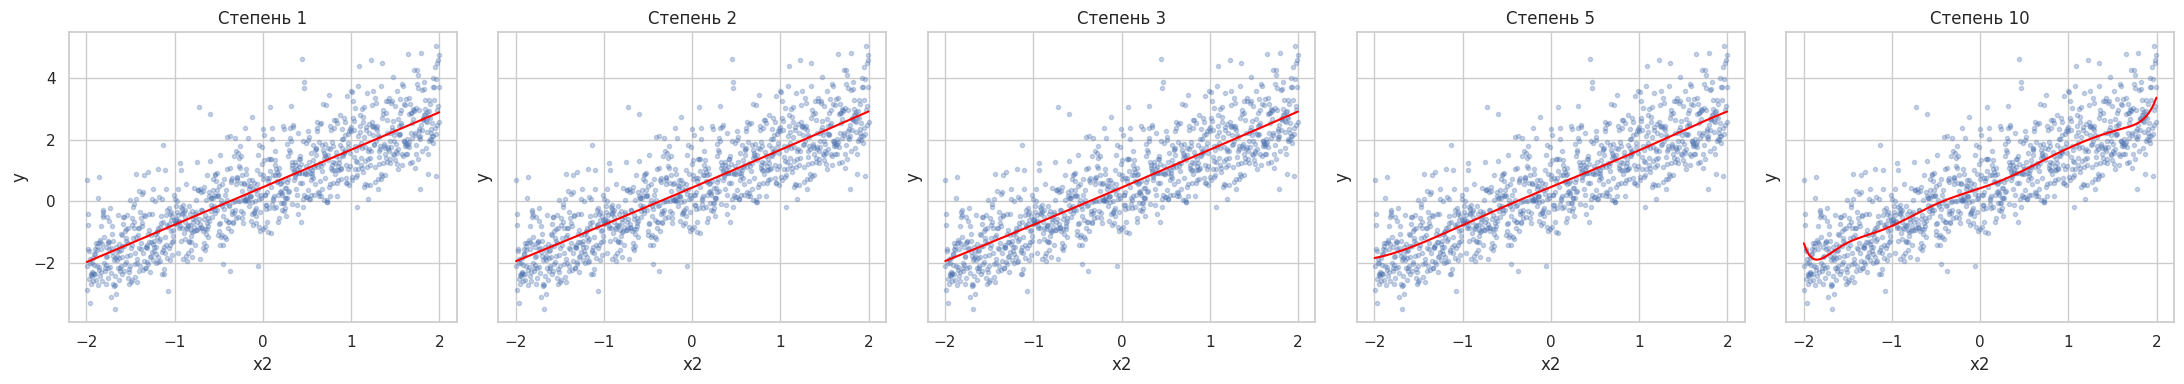

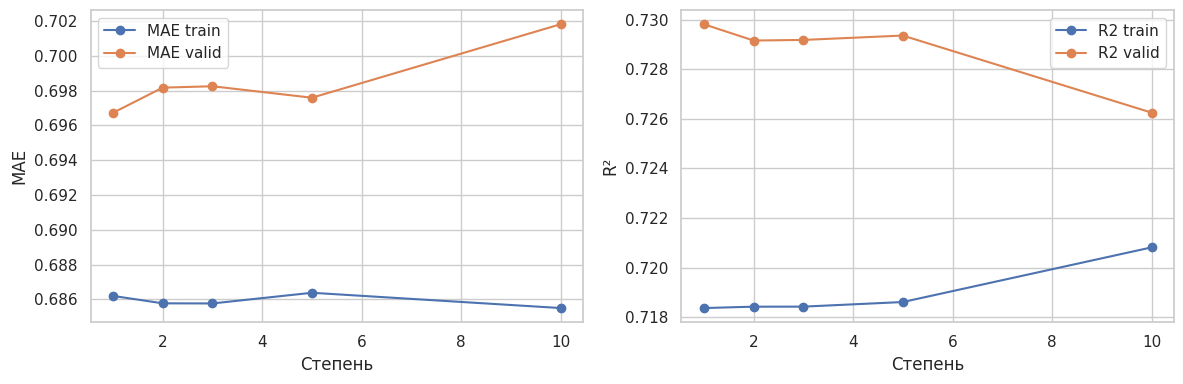

In [6]:
grid = pd.DataFrame({best_feature: np.linspace(reg[best_feature].min(), reg[best_feature].max(), 400)})
fig, axes = plt.subplots(1, len(degrees), figsize=(22, 4), sharey=True)
for ax, degree in zip(axes, degrees):
    ax.scatter(reg[best_feature], reg['y'], s=9, alpha=.3)
    ax.plot(grid[best_feature], poly_models[degree].predict(grid), color='red')
    ax.set(xlabel=best_feature, ylabel='y', title=f'Степень {degree}')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
poly_results[['MAE train', 'MAE valid']].plot(ax=axes[0], marker='o')
poly_results[['R2 train', 'R2 valid']].plot(ax=axes[1], marker='o')
axes[0].set_ylabel('MAE')
axes[1].set_ylabel('R²')
plt.tight_layout()
plt.show()


**Вывод по части 2.** Оптимальна степень, которая даёт небольшую ошибку на новых данных при разумной сложности; универсальной степени нет. Слишком низкая степень может не описать изгиб зависимости (недообучение), слишком высокая — подстроиться под шум и давать нестабильные прогнозы (переобучение). Об этом судят по разрыву train/valid и кросс-валидации. Высокая степень не обязательно лучше, даже если её ошибка на обучении меньше. Результат для выбранного листа выводится ниже.

Для var3 по кросс-валидации выбраны x2 и степень 2. На отложенных строках MAE ≈ 0,698 и R² ≈ 0,729 — практически тот же результат, что у прямой, немного хуже на этом разбиении. Существенного выигрыша от полинома нет; для практического использования здесь достаточно более простой линейной модели. Нельзя объявить нелинейную модель лучше только потому, что она сложнее.


In [7]:
chosen = poly_results.loc[best_degree]
print(f'Лист {SHEET_NAME}: выбран {best_feature}, степень {best_degree}. '
      f'MAE valid = {chosen["MAE valid"]:.4f}, R² valid = {chosen["R2 valid"]:.4f}.')


Лист var3: выбран x2, степень 2. MAE valid = 0.6982, R² valid = 0.7292.


## Часть 3. Прогноз годовой зарплаты
### 3.1. Описание и обзор данных
Набор `salary.csv` содержит характеристики 1500 сотрудников. Целевая переменная — **salary**, годовая зарплата. `income` — доход до текущей работы, это отдельный признак, а не цель.

| Столбец | Смысл |
|---|---|
| age | Возраст, лет |
| income | Годовой доход до текущей работы |
| experience | Полные годы профессионального опыта |
| score_test | Результат профессионального теста |
| hours_worked | Среднее число рабочих часов в неделю |
| distance_to_work | Расстояние до работы |
| savings | Сбережения |
| debt | Текущие долги, доллары |
| education | Уровень образования |
| city | Город проживания |
| job_type | Сфера деятельности |
| marital_status | Семейное положение |
| car | Наличие автомобиля |
| remote_work | Удалённая работа |
| salary | Годовая зарплата — целевой столбец |

Для остальных денежных показателей и расстояния единицы явно не заданы: не приписываю им валюту или километры без подтверждения.


In [8]:
display(salary.head(20))
salary.info()
display(salary.describe())
display(salary.describe(include='object'))
print('Столбцы:', salary.columns.tolist())
print('Пропуски:')
display(salary.isna().sum().to_frame('Количество'))
print('Явных дубликатов:', salary.duplicated().sum())
for column in salary.select_dtypes(include='object'):
    values = salary[column].dropna().unique()
    normalized = pd.Series(values).str.strip().str.casefold()
    print(column, ':', values.tolist(), '; совпадений после нормализации:', normalized.duplicated().sum())

# В исходном файле пропусков и явных/неявных текстовых дубликатов не обнаружено.
# Одинаковые отдельные категории не являются дубликатами сотрудников.
print('Наблюдений с опытом больше возраста − 18:',
      (salary['experience'] > salary['age'] - 18).sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   object 
 9   city              1500 non-null   object 
 10  job_type          1500 non-null   object 
 11  marital_status    1500 non-null   object 
 12  car               1500 non-null   object 
 13  remote_work       1500 non-null   object 
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), object(6)
memory usage: 175.9+ KB
Столбцы: ['age', 'income', 'ex

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842
5,25,11326.768555,3,73.022827,39,4.879219,11916.744037,6431.835876,Bachelor,Los Angeles,IT,Single,No,Yes,49665.609629
6,38,41579.497114,22,87.163120,49,11.706144,33558.588986,12271.330484,PhD,Chicago,Retail,Single,No,Yes,92451.866841
7,56,54713.055994,19,76.671392,38,9.224122,32785.043710,4876.906464,Bachelor,New York,Retail,Single,Yes,Yes,77558.755600
8,36,43636.766522,14,77.635691,72,1.134451,40287.795615,5796.929279,Master,Phoenix,Healthcare,Married,Yes,No,70917.649089
9,40,40306.859573,28,71.729474,58,7.096197,9083.212469,12941.384435,Master,New York,IT,Married,No,No,83196.215231


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


,education,city,job_type,marital_status,car,remote_work
count,1500,1500,1500,1500,1500,1500
unique,4,5,5,3,2,2
top,Bachelor,New York,Retail,Married,Yes,Yes
freq,900,600,500,717,1050,883


,Количество
age,0
income,0
experience,0
score_test,0
hours_worked,0
distance_to_work,0
savings,0
debt,0
education,0
city,0


**Вывод по качеству данных.** В предоставленном файле 1500 строк и 15 столбцов; пропусков и одинаковых строк нет. Названия столбцов пригодны для работы, варианты написания категорий не дублируются. Числовые столбцы имеют числовые типы, категориальные — строки. Искусственное преобразование типов не требуется.

В данных встречаются неправдоподобные сочетания возраста и опыта. Это ограничение качества исходного набора: без сведений об источнике не придумываю исправления и не удаляю строки по предположению о возрасте начала работы. Выводы этой учебной модели нельзя переносить на реальную кадровую политику без проверки данных.


### 3.2. Распределение целевой переменной до обработки


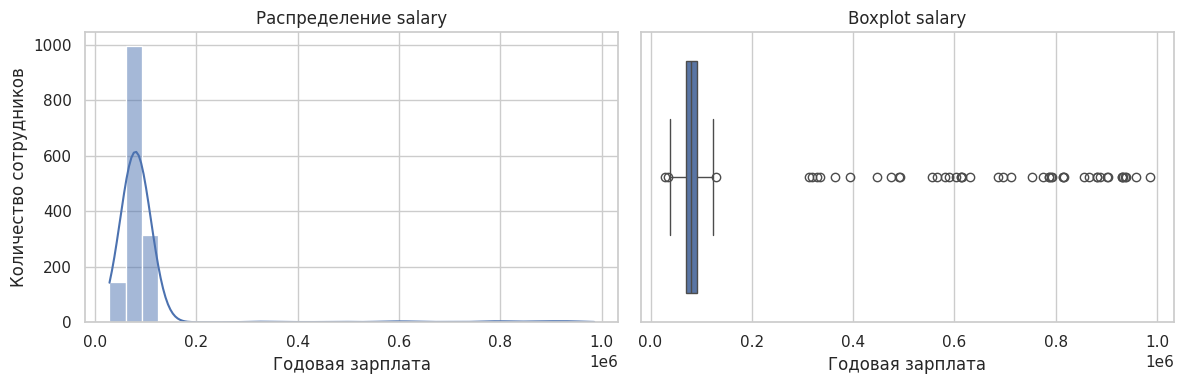

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(salary['salary'], bins=30, kde=True, ax=axes[0])
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников', title='Распределение salary')
sns.boxplot(x=salary['salary'], ax=axes[1])
axes[1].set(xlabel='Годовая зарплата', title='Boxplot salary')
plt.tight_layout()
plt.show()


### 3.3. Разбиение, проверка выбросов и кодирование
Откладываю 25% строк для валидации. Все параметры обработки и подбора моделей рассчитываю только на обучающей части.

По правилу 1,5 IQR отмечаю крайние значения, но не удаляю их автоматически: высокий доход, долг или зарплата сами по себе не являются ошибкой. Нулевые и отрицательные значения проверяю отдельно. Целевую зарплату не обрезаю: иначе меняется сама задача и оценка ошибки становится искусственно лучше.

Числовые признаки стандартизирую. Категориальные кодирую One-Hot с удалением базовой категории. Для образования также использую One-Hot, чтобы не навязывать равные интервалы между уровнями. Все преобразования входят в Pipeline; обучение кодировщика и стандартизатора на всём наборе до разбиения привело бы к утечке данных.


Обучение: (1125, 14) Валидация: (375, 14)
Неположительных salary: 0
Отрицательные числовые значения на train:
После кодирования: (1125, 23)


,За границами 1.5 IQR на train
age,0
income,8
experience,0
score_test,8
hours_worked,0
distance_to_work,54
savings,28
debt,10
salary,38


,Количество
age,0
income,1
experience,0
score_test,0
hours_worked,0
distance_to_work,0
savings,0
debt,0


,num__age,num__income,num__experience,num__score_test,num__hours_worked,num__distance_to_work,num__savings,num__debt,cat__education_High School,cat__education_Master,cat__education_PhD,cat__city_Houston,cat__city_Los Angeles,cat__city_New York,cat__city_Phoenix,cat__job_type_Finance,cat__job_type_Healthcare,cat__job_type_IT,cat__job_type_Retail,cat__marital_status_Married,cat__marital_status_Single,cat__car_Yes,cat__remote_work_Yes
807,-0.583953,-0.584255,0.490151,0.148027,1.385395,0.640189,2.674690,-0.551260,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1229,-1.250432,-0.399771,1.266435,0.891339,-1.369401,-0.209566,-1.066137,-1.401304,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
1480,-1.183784,-1.755500,-1.579938,-0.887493,0.447593,0.193432,0.440914,-1.380614,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1436,0.415764,-0.070914,0.921420,0.283506,-1.662464,0.257812,-0.300634,0.050580,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0
179,1.015594,-0.639517,-1.321177,0.010414,-0.959112,-0.930869,-0.407039,-1.051288,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


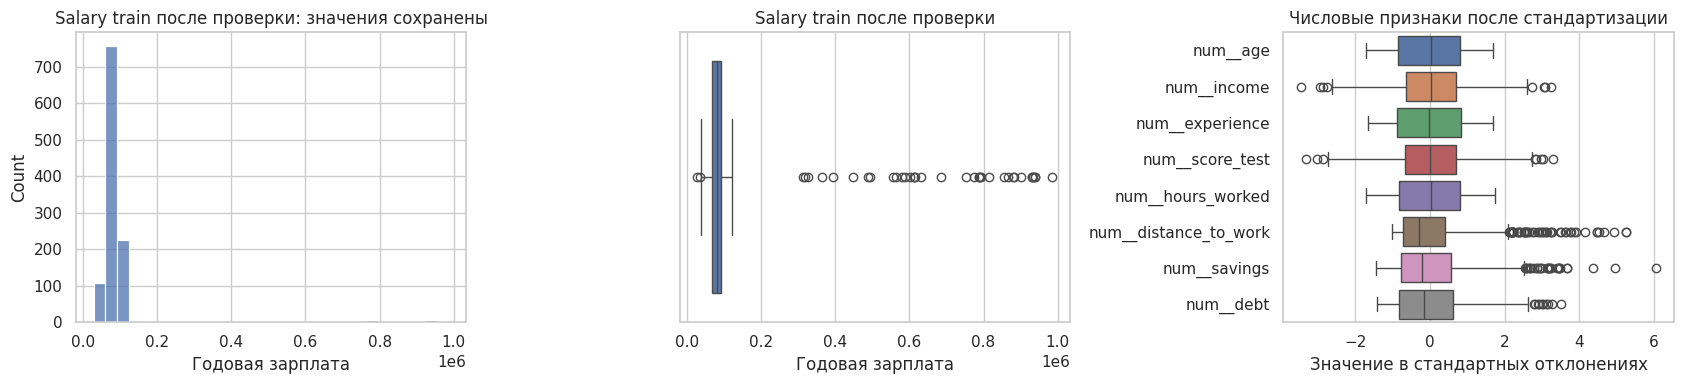

In [10]:
X_salary = salary.drop(columns='salary')
y_salary = salary['salary']
X_train, X_valid, y_train, y_valid = train_test_split(
    X_salary, y_salary, test_size=.25, random_state=RANDOM_STATE)
numeric_columns = X_train.select_dtypes(include='number').columns.tolist()
category_columns = X_train.select_dtypes(exclude='number').columns.tolist()
print('Обучение:', X_train.shape, 'Валидация:', X_valid.shape)

train_for_iqr = X_train[numeric_columns].assign(salary=y_train)
q1, q3 = train_for_iqr.quantile(.25), train_for_iqr.quantile(.75)
iqr = q3 - q1
outlier_counts = ((train_for_iqr < q1 - 1.5 * iqr) |
                  (train_for_iqr > q3 + 1.5 * iqr)).sum()
display(outlier_counts.to_frame('За границами 1.5 IQR на train'))
print('Неположительных salary:', (y_train <= 0).sum())
print('Отрицательные числовые значения на train:')
display((X_train[numeric_columns] < 0).sum().to_frame('Количество'))

numeric_pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
category_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                  OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_columns),
    ('cat', category_pipeline, category_columns)
])
# Показываю результат обработки только train; модели ниже обучат свои копии Pipeline.
from sklearn.base import clone
preview_processor = clone(preprocessor)
train_encoded = pd.DataFrame(preview_processor.fit_transform(X_train),
                             columns=preview_processor.get_feature_names_out(), index=X_train.index)
display(train_encoded.head())
print('После кодирования:', train_encoded.shape)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(y_train, bins=30, ax=axes[0])
axes[0].set(title='Salary train после проверки: значения сохранены', xlabel='Годовая зарплата')
sns.boxplot(x=y_train, ax=axes[1])
axes[1].set(title='Salary train после проверки', xlabel='Годовая зарплата')
sns.boxplot(data=train_encoded.filter(like='num__'), orient='h', ax=axes[2])
axes[2].set(title='Числовые признаки после стандартизации', xlabel='Значение в стандартных отклонениях')
plt.tight_layout()
plt.show()


### 3.4. Матрица диаграмм рассеяния
Для читаемости строю матрицу по числовым признакам и salary на случайной подвыборке train. Случайный отбор касается только рисунка: обучение использует все обучающие строки.


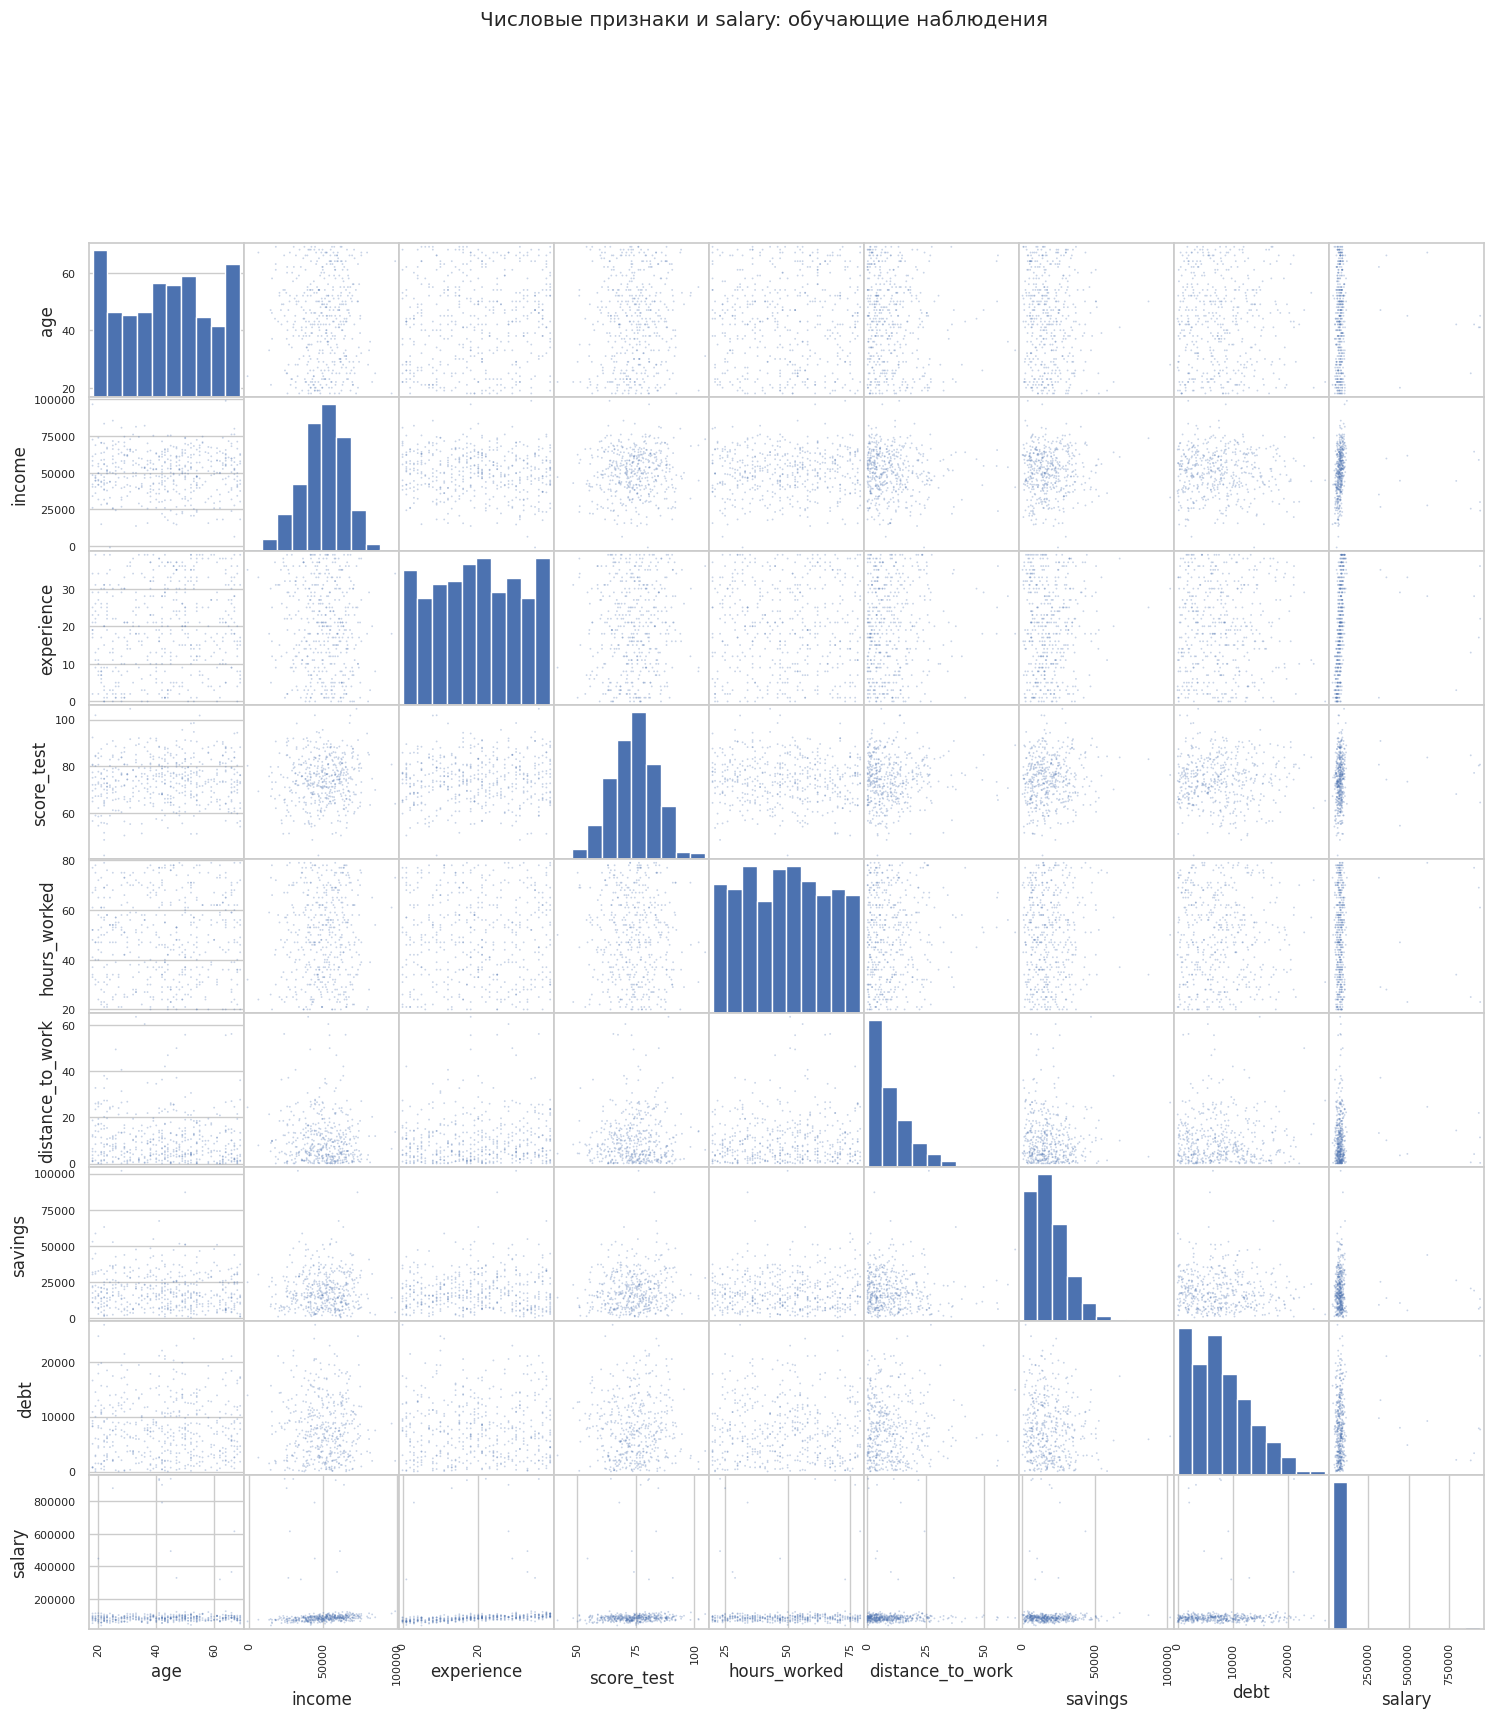

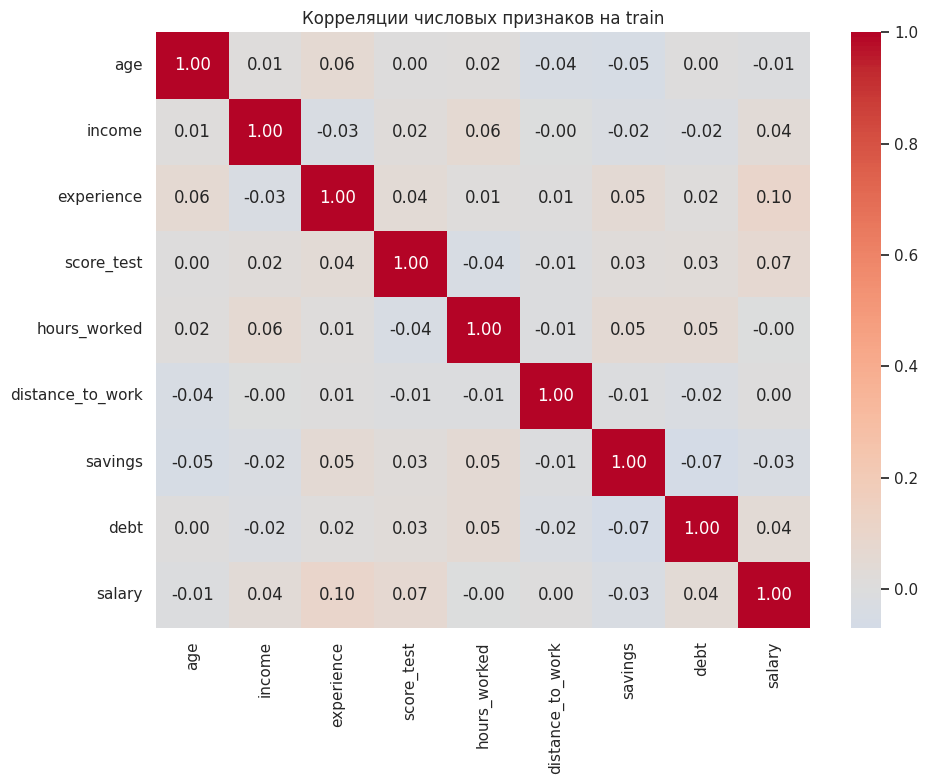

In [11]:
scatter_data = X_train[numeric_columns].assign(salary=y_train)
pd.plotting.scatter_matrix(scatter_data.sample(n=min(450, len(scatter_data)), random_state=RANDOM_STATE),
                           figsize=(18, 18), diagonal='hist', alpha=.3, s=7)
plt.suptitle('Числовые признаки и salary: обучающие наблюдения', y=1.01)
plt.show()
plt.figure(figsize=(10, 8))
sns.heatmap(scatter_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции числовых признаков на train')
plt.tight_layout()
plt.show()


### 3.5. Линейная регрессия, kNN и дерево решений
Линейная регрессия оценивает суммарный вклад признаков. kNN усредняет зарплаты ближайших сотрудников и особенно чувствителен к масштабу. Дерево делит пространство признаков порогами; масштабирование ему не нужно, но общий Pipeline упрощает сравнение.

Для kNN подбираю число соседей и веса, для дерева — глубину и минимальный размер листа. Использую 5-фолд кросс-валидацию на train и одну метрику подбора — MAE. Валидация остаётся общей для всех методов. Дополнительно включаю прогноз среднего как простой ориентир.


In [12]:
def salary_pipeline(estimator):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])

salary_models = {
    'Среднее (ориентир)': salary_pipeline(DummyRegressor(strategy='mean')),
    'Линейная регрессия': salary_pipeline(LinearRegression())
}
for model in salary_models.values():
    model.fit(X_train, y_train)

search_specs = {
    'kNN': (KNeighborsRegressor(), {'model__n_neighbors': [3, 5, 10, 20, 40],
                                    'model__weights': ['uniform', 'distance']}),
    'Дерево решений': (DecisionTreeRegressor(random_state=RANDOM_STATE),
                       {'model__max_depth': [3, 5, 8, None],
                        'model__min_samples_leaf': [5, 15, 30]})
}
salary_searches = {}
for name, (estimator, parameters) in search_specs.items():
    search = GridSearchCV(salary_pipeline(estimator), parameters,
                          scoring='neg_mean_absolute_error', cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    salary_searches[name] = search
    salary_models[name] = search.best_estimator_
    print(name, ':', search.best_params_, '; MAE CV =', round(-search.best_score_, 2))

salary_predictions = {}
quality_rows = []
for name, model in salary_models.items():
    pred = model.predict(X_valid)
    salary_predictions[name] = pred
    quality_rows.append({'Модель': name, **regression_metrics(y_valid, pred),
                         'MAE train': mean_absolute_error(y_train, model.predict(X_train)),
                         'R2 train': r2_score(y_train, model.predict(X_train))})
salary_results = pd.DataFrame(quality_rows).set_index('Модель').sort_values('MAE')
display(salary_results)
best_salary_name = salary_results.drop(index='Среднее (ориентир)')['MAE'].idxmin()
print('Минимальная MAE на валидации:', best_salary_name)

salary_comparison = pd.DataFrame({'Факт salary': y_valid})
for name, pred in salary_predictions.items():
    salary_comparison[name] = pred
with pd.option_context('display.max_rows', None):
    display(salary_comparison.sort_index())


kNN : {'model__n_neighbors': 40, 'model__weights': 'distance'} ; MAE CV = 37935.23
Дерево решений : {'model__max_depth': 3, 'model__min_samples_leaf': 5} ; MAE CV = 40152.17
Минимальная MAE на валидации: kNN


,MAE,MSE,RMSE,R2,MAE train,R2 train
Модель,,,,,,
kNN,33723.774808,1.128432e+10,106227.686870,-0.014310,0.005301,1.000000
Дерево решений,34373.716997,1.148589e+10,107172.229461,-0.032428,37958.831588,0.052259
Линейная регрессия,34926.602195,1.124237e+10,106030.043200,-0.010539,38207.516235,0.026888
Среднее (ориентир),34997.664647,1.113113e+10,105504.170272,-0.000540,39062.274315,0.000000


,Факт salary,Среднее (ориентир),Линейная регрессия,kNN,Дерево решений
15,63876.307670,99185.813775,112623.003372,85022.525379,84084.341305
23,111198.257761,99185.813775,139887.395695,105241.672270,163438.181176
29,44219.056055,99185.813775,87378.767582,114137.624128,84084.341305
30,90837.188701,99185.813775,98469.292869,71987.707546,84084.341305
31,94294.390163,99185.813775,99844.107586,109102.270473,105716.197188
32,91766.966835,99185.813775,102116.764365,102424.154960,84084.341305
43,89125.427373,99185.813775,112672.252438,119999.639364,84084.341305
44,71288.910020,99185.813775,74074.842968,106332.980003,104633.813295
48,87096.671249,99185.813775,120527.831943,111716.438287,105716.197188
49,83843.268389,99185.813775,88307.821332,78293.416557,84084.341305


### 3.6. Коэффициенты линейной модели и важность признаков
Для числовых признаков коэффициент соответствует изменению прогноза при росте признака на **одно стандартное отклонение train**, при прочих равных. Для дамми-признаков — отличию от базовой категории. Это ассоциации, не доказательства причинного влияния. Коэффициенты числовых и бинарных признаков имеют разную интерпретацию, поэтому их модули нельзя безоговорочно считать единым рейтингом важности.


Свободный член: 97819.12094157397
Базовые категории:
education: Bachelor
city: Chicago
job_type: Education
marital_status: Divorced
car: No
remote_work: No
Три наиболее полезных признака по перестановке: experience, education, income


,Признак,Коэффициент,Модуль
10,cat__education_PhD,17472.521023,17472.521023
9,cat__education_Master,15856.336637,15856.336637
16,cat__job_type_Healthcare,10707.261588,10707.261588
2,num__experience,10702.749567,10702.749567
21,cat__car_Yes,-9121.907491,9121.907491
18,cat__job_type_Retail,8640.591030,8640.591030
20,cat__marital_status_Single,-8050.602535,8050.602535
22,cat__remote_work_Yes,7960.047658,7960.047658
3,num__score_test,7631.885254,7631.885254
19,cat__marital_status_Married,-7299.613168,7299.613168


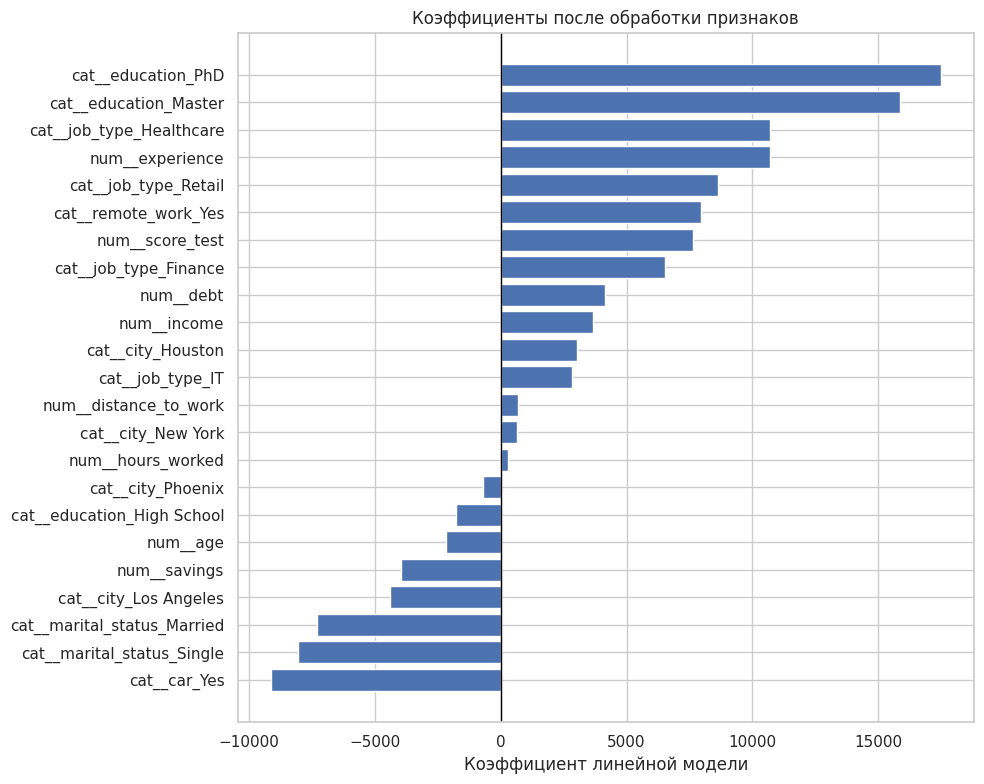

,Признак,Рост MAE при перестановке,Стандартное отклонение
2,experience,2895.501202,234.766901
8,education,1066.423137,165.595109
1,income,649.722880,165.582100
12,car,159.915386,126.801926
3,score_test,121.189439,188.920684
7,debt,43.526075,96.168989
0,age,22.624706,93.601582
4,hours_worked,0.907254,9.363035
13,remote_work,-44.384418,121.496878
5,distance_to_work,-54.455976,18.998673


In [13]:
linear_salary = salary_models['Линейная регрессия']
fitted_preprocessor = linear_salary.named_steps['preprocess']
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = pd.DataFrame({'Признак': feature_names,
                             'Коэффициент': linear_salary.named_steps['model'].coef_})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
coefficients = coefficients.sort_values('Модуль', ascending=False)
display(coefficients)
print('Свободный член:', linear_salary.named_steps['model'].intercept_)
encoder = fitted_preprocessor.named_transformers_['cat'].named_steps['onehotencoder']
print('Базовые категории:')
for name, categories, drop_index in zip(category_columns, encoder.categories_, encoder.drop_idx_):
    print(f'{name}: {categories[drop_index]}')

fig, ax = plt.subplots(figsize=(10, 8))
plot_coefs = coefficients.sort_values('Коэффициент')
ax.barh(plot_coefs['Признак'], plot_coefs['Коэффициент'])
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='Коэффициент линейной модели', title='Коэффициенты после обработки признаков')
plt.tight_layout()
plt.show()

# Для сопоставления исходных признаков использую падение качества при перестановке.
# Это дополнительная интерпретация на валидации, а не подбор нового набора признаков.
from sklearn.inspection import permutation_importance
importance = permutation_importance(linear_salary, X_valid, y_valid,
                                    scoring='neg_mean_absolute_error', n_repeats=10,
                                    random_state=RANDOM_STATE)
importance_table = pd.DataFrame({'Признак': X_valid.columns,
                                 'Рост MAE при перестановке': importance.importances_mean,
                                 'Стандартное отклонение': importance.importances_std})
importance_table = importance_table.sort_values('Рост MAE при перестановке', ascending=False)
display(importance_table)
print('Три наиболее полезных признака по перестановке:',
      ', '.join(importance_table.head(3)['Признак']))


### 3.7. Факт–прогноз и остатки
Остаток определяю как факт минус прогноз. На графике факт–прогноз красная диагональ соответствует идеальному совпадению. На графике остатков хорошая модель даёт облако около нуля без выраженного изгиба. Воронка указывает на изменение разброса ошибок, отдельные далёкие точки — на крупные ошибки.


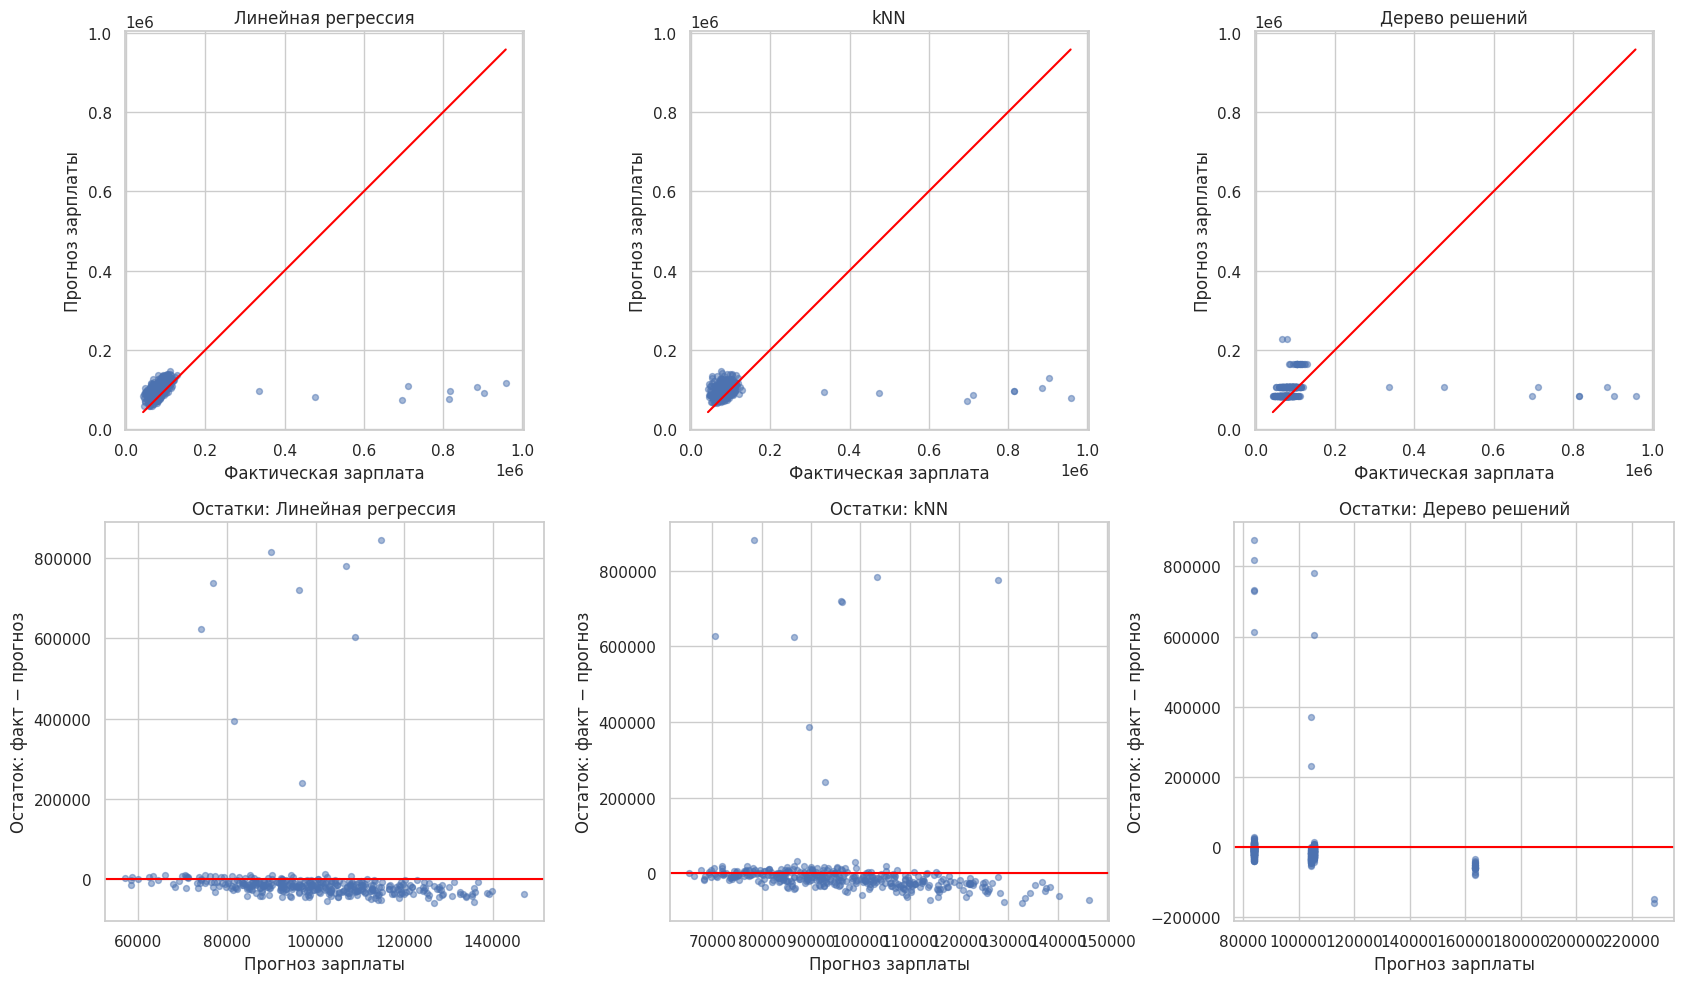

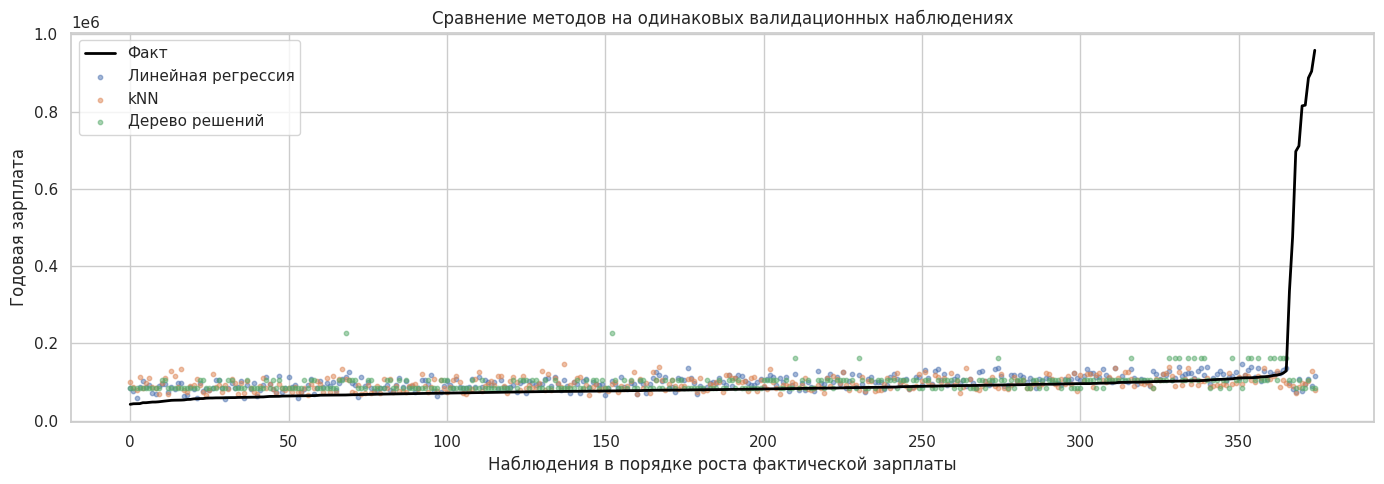

In [14]:
names = ['Линейная регрессия', 'kNN', 'Дерево решений']
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for col, name in enumerate(names):
    pred = salary_predictions[name]
    lo, hi = min(y_valid.min(), pred.min()), max(y_valid.max(), pred.max())
    axes[0, col].scatter(y_valid, pred, alpha=.5, s=18)
    axes[0, col].plot([lo, hi], [lo, hi], color='red')
    axes[0, col].set(xlabel='Фактическая зарплата', ylabel='Прогноз зарплаты', title=name)
    axes[0, col].set_aspect('equal', adjustable='box')
    axes[1, col].scatter(pred, y_valid.to_numpy() - pred, alpha=.5, s=18)
    axes[1, col].axhline(0, color='red')
    axes[1, col].set(xlabel='Прогноз зарплаты', ylabel='Остаток: факт − прогноз', title=f'Остатки: {name}')
plt.tight_layout()
plt.show()

# Общие наблюдения для трёх методов; сортировка по факту упрощает сравнение.
order = np.argsort(y_valid.to_numpy())
plt.figure(figsize=(14, 5))
plt.plot(y_valid.to_numpy()[order], color='black', linewidth=2, label='Факт')
for name in names:
    plt.scatter(np.arange(len(order)), salary_predictions[name][order], s=10, alpha=.5, label=name)
plt.xlabel('Наблюдения в порядке роста фактической зарплаты')
plt.ylabel('Годовая зарплата')
plt.title('Сравнение методов на одинаковых валидационных наблюдениях')
plt.legend()
plt.tight_layout()
plt.show()


### 3.8. Вывод по моделям зарплаты
Итоговые численные результаты и средний знак остатков вывожу из рассчитанных таблиц. Положительный средний остаток означает занижение прогноза в среднем, отрицательный — завышение. Небольшое среднее само по себе не означает малую ошибку: большие ошибки разных знаков могут компенсироваться.


In [15]:
for name in names:
    row = salary_results.loc[name]
    residuals = y_valid.to_numpy() - salary_predictions[name]
    print(f'{name}: MAE = {row["MAE"]:.2f}; RMSE = {row["RMSE"]:.2f}; '
          f'R² = {row["R2"]:.4f}; средний остаток = {residuals.mean():.2f}.')
    print(f'  MAE train = {row["MAE train"]:.2f}; '
          f'разница MAE valid − train = {row["MAE"] - row["MAE train"]:.2f}.')
print(f'Среди трёх основных методов минимальная MAE у: {best_salary_name}, '
      'по минимальной MAE на общем отложенном наборе.')
print('Это сравнение на одном разбиении; для производственного применения нужна независимая проверка.')

print('У всех трёх методов R² отрицателен: ни один не даёт удовлетворительного результата по квадрату ошибки. Выбор по MAE и по RMSE различается.')


Линейная регрессия: MAE = 34926.60; RMSE = 106030.04; R² = -0.0105; средний остаток = -3199.69.
  MAE train = 38207.52; разница MAE valid − train = -3280.91.
kNN: MAE = 33723.77; RMSE = 106227.69; R² = -0.0143; средний остаток = 315.54.
  MAE train = 0.01; разница MAE valid − train = 33723.77.
Дерево решений: MAE = 34373.72; RMSE = 107172.23; R² = -0.0324; средний остаток = -1517.96.
  MAE train = 37958.83; разница MAE valid − train = -3585.11.
Среди трёх основных методов минимальная MAE у: kNN, по минимальной MAE на общем отложенном наборе.
Это сравнение на одном разбиении; для производственного применения нужна независимая проверка.
У всех трёх методов R² отрицателен: ни один не даёт удовлетворительного результата по квадрату ошибки. Выбор по MAE и по RMSE различается.


### 3.9. Влияние крайних зарплат: дополнительная проверка
В исходных данных максимальная зарплата около 986 тысяч при медиане около 80 тысяч. Все три основные модели на полной валидации имеют отрицательный R². Это означает, что по квадрату ошибки они не превосходят прогноз среднего самой валидационной выборки. Поэтому минимальная MAE среди трёх моделей ещё не означает хорошее качество.

Проверю чувствительность линейной регрессии к крайним зарплатам: обучу дополнительную модель на строках train внутри границ 1,5 IQR. Порог вычисляю только на train. Это учебный эксперимент с изменённой обучающей выборкой, а не доказательство, что крайние зарплаты ошибочны. **Валидацию не фильтрую и не обрезаю.** Для MAE добавляю подходящий простой ориентир — медиану train.

Почти нулевая ошибка kNN на train объясняется весами `distance`: при прогнозе обучающей точки она сама становится соседом на нулевом расстоянии. Эту оценку нельзя считать подтверждением способности предсказывать новые объекты.


Границы по train: [36490.42, 123826.29]. Для эксперимента исключено 38 из 1125 строк train.
Валидация сохранена полностью: 375 строк.
Для дополнительной модели MAE train рассчитана на полном train для сопоставимости.
Изменение MAE линейной регрессии: 34926.60 → 20703.27.
Результат зависит от определения задачи: для всей популяции нужны данные о причинах крайних зарплат.


,MAE,MSE,RMSE,R2,MAE train,R2 train
Модель,,,,,,
Линейная (IQR только train),20703.268824,1.128191e+10,106216.314481,-0.014093,23799.244128,-0.015136
Медиана (ориентир),28119.215384,1.139574e+10,106750.843835,-0.024325,31120.968123,-0.027608
kNN,33723.774808,1.128432e+10,106227.686870,-0.014310,0.005301,1.000000
Дерево решений,34373.716997,1.148589e+10,107172.229461,-0.032428,37958.831588,0.052259
Линейная регрессия,34926.602195,1.124237e+10,106030.043200,-0.010539,38207.516235,0.026888
Среднее (ориентир),34997.664647,1.113113e+10,105504.170272,-0.000540,39062.274315,0.000000


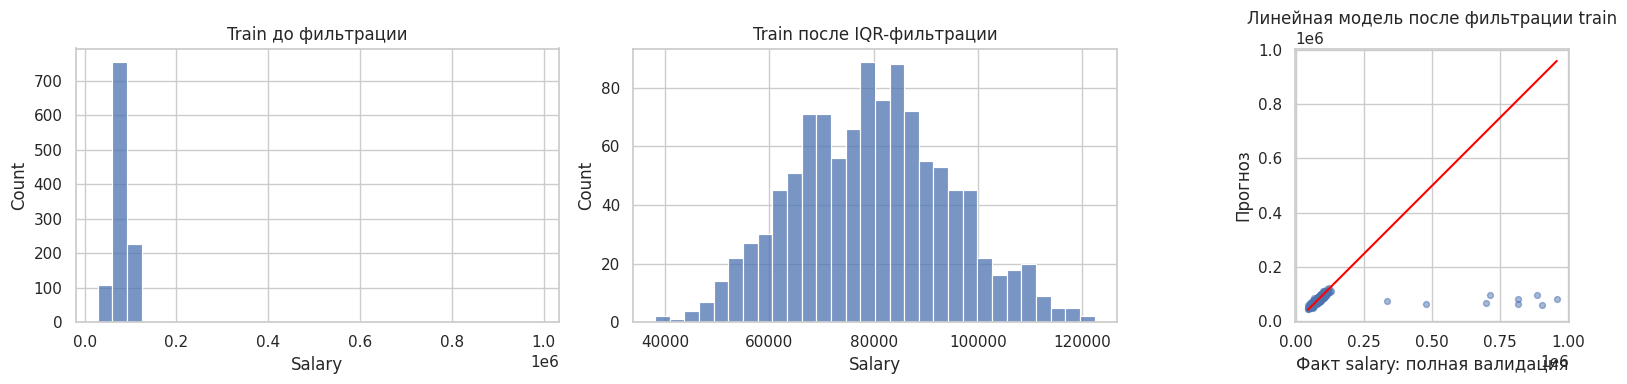

In [16]:
salary_lower = q1['salary'] - 1.5 * iqr['salary']
salary_upper = q3['salary'] + 1.5 * iqr['salary']
keep_train = y_train.between(salary_lower, salary_upper)
print(f'Границы по train: [{salary_lower:.2f}, {salary_upper:.2f}]. '
      f'Для эксперимента исключено {(~keep_train).sum()} из {len(keep_train)} строк train.')
print('Валидация сохранена полностью:', len(y_valid), 'строк.')
filtered_linear = salary_pipeline(LinearRegression())
filtered_linear.fit(X_train.loc[keep_train], y_train.loc[keep_train])
median_baseline = salary_pipeline(DummyRegressor(strategy='median'))
median_baseline.fit(X_train, y_train)
additional_models = {'Линейная (IQR только train)': filtered_linear,
                     'Медиана (ориентир)': median_baseline}
sensitivity_rows = []
for name, model in additional_models.items():
    prediction = model.predict(X_valid)
    sensitivity_rows.append({'Модель': name, **regression_metrics(y_valid, prediction),
                             'MAE train': mean_absolute_error(y_train, model.predict(X_train)),
                             'R2 train': r2_score(y_train, model.predict(X_train))})
all_results = pd.concat([salary_results, pd.DataFrame(sensitivity_rows).set_index('Модель')]).sort_values('MAE')
display(all_results)
print('Для дополнительной модели MAE train рассчитана на полном train для сопоставимости.')
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(y_train, bins=30, ax=axes[0])
axes[0].set(title='Train до фильтрации', xlabel='Salary')
sns.histplot(y_train.loc[keep_train], bins=30, ax=axes[1])
axes[1].set(title='Train после IQR-фильтрации', xlabel='Salary')
prediction = filtered_linear.predict(X_valid)
axes[2].scatter(y_valid, prediction, alpha=.5, s=18)
lo, hi = min(y_valid.min(), prediction.min()), max(y_valid.max(), prediction.max())
axes[2].plot([lo, hi], [lo, hi], color='red')
axes[2].set(xlabel='Факт salary: полная валидация', ylabel='Прогноз', title='Линейная модель после фильтрации train')
axes[2].set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()
base_mae = salary_results.loc['Линейная регрессия', 'MAE']
new_mae = all_results.loc['Линейная (IQR только train)', 'MAE']
print(f'Изменение MAE линейной регрессии: {base_mae:.2f} → {new_mae:.2f}.')
print('Результат зависит от определения задачи: для всей популяции нужны данные о причинах крайних зарплат.')


## Общий вывод
В работе рассмотрены синтетические зависимости `y` от `x1` и `x2` и прогноз годовой зарплаты по характеристикам сотрудников. Для парной регрессии сравниваются коэффициенты корреляции, две линейные модели и их ошибки. Для полиномиальной регрессии признак и степень выбираются по кросс-валидации внутри обучающей выборки; сравнение train/valid помогает обнаружить недообучение и переобучение. Для варианта 13 использован лист var3. По кросс-валидации выбраны признак x2 и полином второй степени.

В данных о зарплате нет пропусков и дубликатов. Экстремальные значения проверены по IQR и сохранены: без подтверждения ошибки удалять их необоснованно. Для количественных признаков применена стандартизация, для категорий — One-Hot. Преобразования обучаются только на train. Сравнены линейная регрессия, kNN и дерево решений с общим разбиением и четырьмя метриками; параметры kNN и дерева подобраны по обучающей кросс-валидации. Качество сопоставлено с прогнозом среднего, а интерпретация дополнена коэффициентами, перестановочной важностью и графиками остатков.

Среди основных методов kNN имеет минимальную MAE (около 33 724), но все три модели дают отрицательный R². Линейная регрессия имеет меньший RMSE среди трёх методов, однако уступает простому прогнозу среднего train по RMSE. Следовательно, объявить одну модель хорошей по всем критериям нельзя. После исключения 38 крайних строк только из train MAE линейной модели снизилась с 34 926,60 до 20 703,27 на той же полной валидации. Это лучше медианного ориентира (MAE 28 119,22), но R² остаётся отрицательным (−0,0141): крайние зарплаты по-прежнему предсказываются плохо. Для уменьшения обычной абсолютной ошибки разумно рассмотреть такую линейную модель, а для прогноза редких высоких зарплат требуются дополнительные признаки и проверка источника данных. Они описывают качество на отложенной части этого набора. Неправдоподобные сочетания возраста и стажа ограничивают содержательную интерпретацию, а связи признаков с зарплатой не доказывают причинность.

## Дополнительное задание №13. Графики остатков и прогнозов
В методичке дополнительные задания выдаются преподавателем после защиты; номер варианта не назван правилом их распределения. Задание №13 показано как дополнительный материал, без предположения, что оно обязательно назначено варианту 13. Графики и пояснения выполнены в разделах 3.7–3.8 для всех трёх основных моделей.

## Перед сдачей
Указать ФИО и группу, выполнить все ячейки для выбранного листа var3. После импорта ноутбука в Colab сохранить его на Google Диск и открыть преподавателю доступ по ссылке. Отдельный отчёт с титульным листом и иллюстрациями, требуемый методичкой, не заменяется одним ноутбуком.
